# MGSC 661 Final Project | Part B
## Model comparison and evaluation

Compare a majority-class baseline, two logistic models, and a random forest on the
train/test split supplied by Part A. Test whether the interaction between funding goal
and campaign duration improves fit, then evaluate how well the models identify failed
campaigns.


## 1. Import libraries

**Purpose.** Load the packages for model fitting, cross-validation, evaluation, and plotting.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import Markdown, display
from scipy.stats import chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from tqdm import tqdm

## 2. Load the data

**Purpose.** Use Part A's original split and model specification.

In [2]:
part_a = Path("Part A")
if not part_a.is_dir():
    part_a = Path("../Part A")

train_data = pd.read_csv(part_a / "train_data.csv", index_col=0)
test_data = pd.read_csv(part_a / "test_data.csv", index_col=0)
model_spec = json.loads((part_a / "model_spec.json").read_text(encoding="utf-8"))

## 3. Summarize class balance

**Purpose.** See how common each outcome is and identify the majority class using the training set.

In [3]:
y_train = train_data["Success"].astype(int)
y_test = test_data["Success"].astype(int)
class_names = {0: "Failure", 1: "Success"}
majority_class = int(y_train.mode().iloc[0])

class_counts = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Test": y_test.value_counts(),
}).sort_index()
display(class_counts.rename(index=class_names))
print(f"Training-set majority class: {class_names[majority_class]}")

,Training,Test
Success,,
Failure,2001,501
Success,10003,2501


Training-set majority class: Success


## 4. Define the predictors

**Purpose.** Set up the two nested logistic models and a raw-goal sensitivity check.

In [4]:
interaction = "Target_x_Duration"
full_predictors = model_spec["predictors"]
main_effects_predictors = [column for column in full_predictors if column != interaction]
raw_predictors = [
    {
        "Log2_Target_c": "Target_1000_c",
        interaction: "Raw_Target_x_Duration",
    }.get(column, column)
    for column in full_predictors
]

## 5. Construct centered features

**Purpose.** Recompute centering from the rows used for fitting so each validation fold uses its own training means.

In [5]:
center_columns = ["Log2_Target", "Duration_10", "Target"]

def make_features(data, centers):
    features = data[full_predictors].astype(float).copy()
    features["Log2_Target_c"] = data["Log2_Target"] - centers["Log2_Target"]
    features["Duration_10_c"] = data["Duration_10"] - centers["Duration_10"]
    features[interaction] = features["Log2_Target_c"] * features["Duration_10_c"]

    features["Target_1000_c"] = (data["Target"] - centers["Target"]) / 1_000
    features["Raw_Target_x_Duration"] = features["Target_1000_c"] * features["Duration_10_c"]
    return features

## 6. Fit the nested logistic models

**Purpose.** Fit both models on all training rows, changing only the interaction term.

In [6]:
def logistic_design(features, predictors):
    return sm.add_constant(features[predictors], has_constant="add")

training_centers = train_data[center_columns].mean()
train_features = make_features(train_data, training_centers)

full_logit = sm.Logit(
    y_train, logistic_design(train_features, full_predictors), missing="raise"
).fit(disp=False)
main_effects_logit = sm.Logit(
    y_train, logistic_design(train_features, main_effects_predictors), missing="raise"
).fit(disp=False)

part_a_coefficients = pd.Series(model_spec["coefficients"])
max_difference = (full_logit.params - part_a_coefficients).abs().max()
print(f"Largest coefficient difference from Part A: {max_difference:.2e}")

Largest coefficient difference from Part A: 2.36e-16


## 7. Test the interaction for H3

**Purpose.** Compare the training-set log-likelihoods of the nested models with a likelihood-ratio test.

In [7]:
lr_statistic = 2 * (full_logit.llf - main_effects_logit.llf)
lr_df = int(full_logit.df_model - main_effects_logit.df_model)
lr_p_value = chi2.sf(lr_statistic, lr_df)
interaction_coef = full_logit.params[interaction]

h3_results = pd.DataFrame([{
    "Main-effects log-likelihood": main_effects_logit.llf,
    "Interaction log-likelihood": full_logit.llf,
    "LR statistic": lr_statistic,
    "Degrees of freedom": lr_df,
    "p-value": lr_p_value,
    "Interaction coefficient": interaction_coef,
}])
display(h3_results.round(5))

,Main-effects log-likelihood,Interaction log-likelihood,LR statistic,Degrees of freedom,p-value,Interaction coefficient
0,-4201.0565,-4196.84572,8.42157,1,0.00371,-0.03483


## 8. Define the random forest benchmark

**Purpose.** Set a reproducible forest and use the same configuration in cross-validation and the final fit.

In [8]:
seed = 42
baseline_name = "Majority baseline"
full_name = "Logistic with interaction"
main_effects_name = "Main-effects logistic"
forest_name = "Random forest"
weighted_name = "Class-weighted logistic"
raw_name = "Raw-goal logistic"

def make_forest():
    return RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, random_state=seed, n_jobs=-1
    )

## 9. Generate out-of-fold failure scores

**Purpose.** Train on four folds and predict the fifth. The progress bar shows elapsed and remaining training time.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
cv_models = [full_name, main_effects_name, forest_name, weighted_name, raw_name]
oof_scores = pd.DataFrame(index=train_data.index, columns=cv_models, dtype=float)

folds = cv.split(train_data, y_train)
for fit_idx, val_idx in tqdm(folds, total=cv.n_splits, desc="Training folds", file=sys.stdout):
    fit_rows = train_data.iloc[fit_idx]
    val_rows = train_data.iloc[val_idx]
    fit_y = y_train.iloc[fit_idx]
    fold_centers = fit_rows[center_columns].mean()

    fit_features = make_features(fit_rows, fold_centers)
    val_features = make_features(val_rows, fold_centers)

    for name, predictors in [
        (full_name, full_predictors),
        (main_effects_name, main_effects_predictors),
        (raw_name, raw_predictors),
    ]:
        model = sm.Logit(fit_y, logistic_design(fit_features, predictors)).fit(disp=False)
        oof_scores.loc[val_rows.index, name] = 1 - model.predict(
            logistic_design(val_features, predictors)
        )

    weighted_logit = sm.GLM(
        fit_y,
        logistic_design(fit_features, full_predictors),
        family=sm.families.Binomial(),
        freq_weights=compute_sample_weight("balanced", fit_y),
    ).fit()
    oof_scores.loc[val_rows.index, weighted_name] = 1 - weighted_logit.predict(
        logistic_design(val_features, full_predictors)
    )

    fold_forest = make_forest().fit(fit_features[full_predictors], fit_y)
    oof_scores.loc[val_rows.index, forest_name] = fold_forest.predict_proba(
        val_features[full_predictors]
    )[:, 0]

Training folds: 100%|████████████████████████████| 5/5 [00:02<00:00,  1.94it/s]


## 10. Select failure thresholds

**Purpose.** Maximize failure-class F1 on the pooled out-of-fold predictions. Fix these thresholds before scoring the test set.

In [10]:
train_failed = y_train.eq(0)
cv_results = []
for name, scores in oof_scores.items():
    precision, recall, thresholds = precision_recall_curve(train_failed, scores)
    precision, recall = precision[:-1], recall[:-1]
    denominator = precision + recall
    f1 = np.divide(
        2 * precision * recall,
        denominator,
        out=np.zeros_like(denominator),
        where=denominator > 0,
    )
    best = np.flatnonzero(np.isclose(f1, f1.max(), rtol=0, atol=1e-12))[-1]
    cv_results.append({
        "Model": name,
        "Failure threshold": thresholds[best],
        "OOF AUC": roc_auc_score(train_failed, scores),
        "OOF failure F1": f1[best],
    })

threshold_table = pd.DataFrame(cv_results).set_index("Model")
display(threshold_table.round(4))

,Failure threshold,OOF AUC,OOF failure F1
Model,,,
Logistic with interaction,0.2862,0.8160,0.5108
Main-effects logistic,0.2854,0.8167,0.5131
Random forest,0.3065,0.8125,0.5075
Class-weighted logistic,0.6353,0.8155,0.5092
Raw-goal logistic,0.2300,0.7881,0.4776


## 11. Train the final random forest

**Purpose.** Fit the benchmark on all training rows after the thresholds have been selected.

In [11]:
final_forest = make_forest()
with tqdm(total=1, desc="Final forest fit", file=sys.stdout) as progress:
    final_forest.fit(train_features[full_predictors], y_train)
    progress.update()

Final forest fit: 100%|██████████████████████████| 1/1 [00:00<00:00,  2.65it/s]


## 12. Score the held-out test set

**Purpose.** Obtain failure probabilities and class predictions from the four comparison models.

In [12]:
test_features = make_features(test_data, training_centers)
test_scores = pd.DataFrame({
    baseline_name: float(train_failed.mean()),
    main_effects_name: 1 - main_effects_logit.predict(
        logistic_design(test_features, main_effects_predictors)
    ),
    full_name: 1 - full_logit.predict(logistic_design(test_features, full_predictors)),
    forest_name: final_forest.predict_proba(test_features[full_predictors])[:, 0],
}, index=test_data.index)

test_predictions = pd.DataFrame({baseline_name: majority_class}, index=test_data.index)
for name in [main_effects_name, full_name, forest_name]:
    threshold = threshold_table.loc[name, "Failure threshold"]
    test_predictions[name] = np.where(test_scores[name] >= threshold, 0, 1)

## 13. Compare test metrics

**Purpose.** Report ROC AUC from the scores and class-specific precision, recall, and F1 from the predictions.

In [13]:
test_results = []
for name, predictions in test_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, labels=[0, 1], zero_division=0
    )
    test_results.append({
        "Model": name,
        "ROC AUC": roc_auc_score(y_test.eq(0), test_scores[name]),
        "Failure precision": precision[0],
        "Failure recall": recall[0],
        "Failure F1": f1[0],
        "Success precision": precision[1],
        "Success recall": recall[1],
        "Success F1": f1[1],
    })

comparison = pd.DataFrame(test_results).set_index("Model")
display(comparison.round(3))

,ROC AUC,Failure precision,Failure recall,Failure F1,Success precision,Success recall,Success F1
Model,,,,,,,
Majority baseline,0.500,0.000,0.000,0.000,0.833,1.000,0.909
Main-effects logistic,0.813,0.438,0.567,0.494,0.908,0.854,0.880
Logistic with interaction,0.814,0.446,0.563,0.498,0.908,0.860,0.883
Random forest,0.817,0.474,0.523,0.497,0.902,0.884,0.893


## 14. Plot the test ROC curves

**Purpose.** Compare how the models rank failed campaigns across thresholds. The baseline's constant score produces the diagonal.

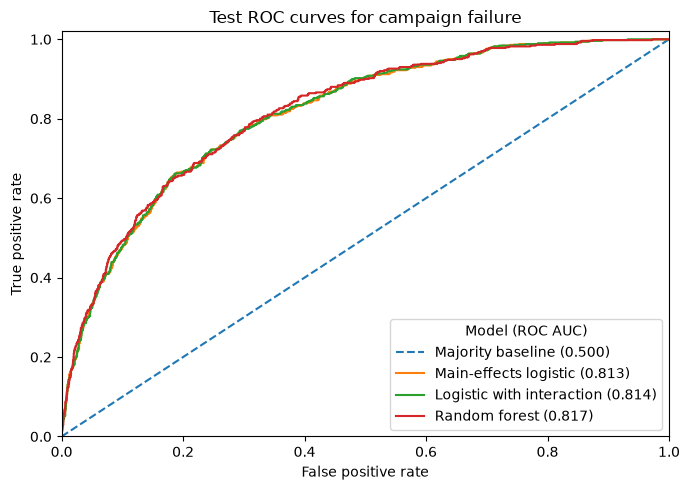

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, scores in test_scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test.eq(0), scores)
    auc = comparison.loc[name, "ROC AUC"]
    ax.plot(
        false_positive_rate, true_positive_rate,
        label=f"{name} ({auc:.3f})",
        linestyle="--" if name == baseline_name else "-",
    )
ax.set(
    title="Test ROC curves for campaign failure",
    xlabel="False positive rate",
    ylabel="True positive rate",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", title="Model (ROC AUC)")
fig.tight_layout()
plt.show()

## 15. Plot the test confusion matrices

**Purpose.** Show how many actual failures and successes each model predicts at its selected operating threshold.

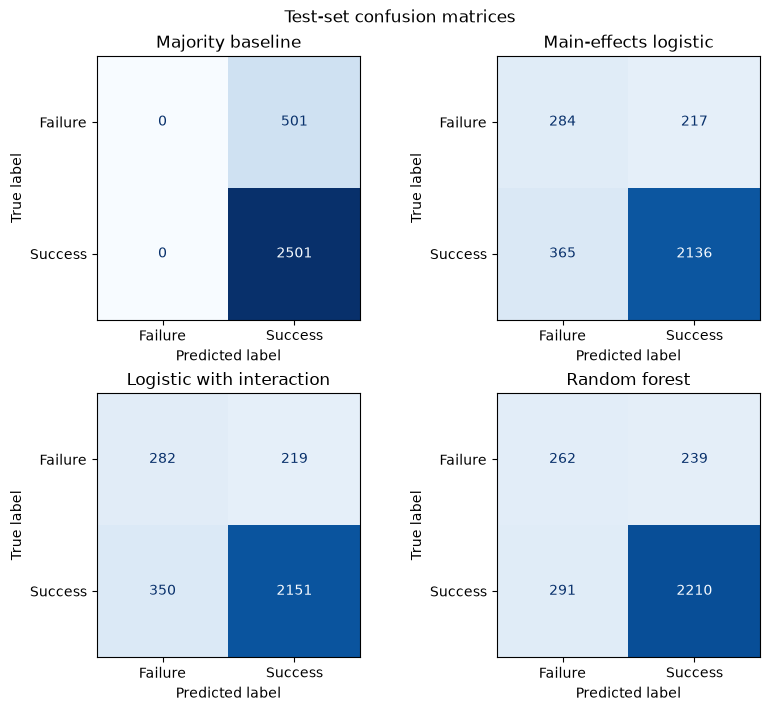

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7), layout="constrained")
matrices = {
    name: confusion_matrix(y_test, predictions, labels=[0, 1])
    for name, predictions in test_predictions.items()
}
max_count = max(matrix.max() for matrix in matrices.values())
for ax, (name, matrix) in zip(axes.flat, matrices.items()):
    plot = ConfusionMatrixDisplay(matrix, display_labels=["Failure", "Success"])
    plot.plot(ax=ax, cmap="Blues", colorbar=False, im_kw={"vmin": 0, "vmax": max_count})
    ax.set_title(name)
fig.suptitle("Test-set confusion matrices")
plt.show()

## 16. Summarize the findings

**Purpose.** Record the H3 result, explain the choice of logistic regression, and document the alternatives tested.

In [16]:
main_cv = threshold_table.loc[full_name]
weighted_cv = threshold_table.loc[weighted_name]
raw_cv = threshold_table.loc[raw_name]
lr_decision = (
    "The test supports including the interaction at the 5% level."
    if lr_p_value < 0.05
    else "The test provides insufficient evidence for including the interaction at the 5% level."
)
direction = "more negative" if interaction_coef < 0 else "more positive"
if interaction_coef == 0:
    direction = "unchanged"

display(Markdown(f"""
### H3: Funding goal and campaign duration

The likelihood-ratio test comparing the nested logistic models gave
χ²({lr_df}) = {lr_statistic:.3f}, p = {lr_p_value:.4f}. {lr_decision}
The interaction coefficient was {interaction_coef:.4f}. With other predictors fixed,
the effect of doubling the goal on the log-odds of success becomes {direction}
as campaign duration increases.

### Why retain the interaction logistic model?

We use logistic regression for the main analysis because it provides interpretable
coefficients and odds ratios for the project hypotheses. On the test set, the
interaction model achieved ROC AUC {comparison.loc[full_name, "ROC AUC"]:.3f}
and failure F1 {comparison.loc[full_name, "Failure F1"]:.3f}, compared with
{comparison.loc[forest_name, "ROC AUC"]:.3f} and
{comparison.loc[forest_name, "Failure F1"]:.3f} for the random forest.
The forest provides a flexible prediction benchmark. The logistic model
provides the estimated interaction and the likelihood-ratio test for H3.

### Alternatives tested

- **Class-weighted logistic regression.** Its out-of-fold AUC was
  {weighted_cv["OOF AUC"]:.3f} and its threshold-tuned failure F1 was
  {weighted_cv["OOF failure F1"]:.3f}. The unweighted interaction model scored
  {main_cv["OOF AUC"]:.3f} and {main_cv["OOF failure F1"]:.3f}, respectively.
  We kept Part A's unweighted fit for inference and addressed failure detection
  through a threshold selected on training data.
- **Raw funding goal.** Replacing the log goal and its interaction with the
  raw goal in thousands of dollars and its interaction yielded out-of-fold
  AUC {raw_cv["OOF AUC"]:.3f} and failure F1 {raw_cv["OOF failure F1"]:.3f}.
  We kept the log scale so the effect can be expressed per doubling of the goal.
- **Random forest as the main model.** We retained the forest as a predictive
  comparison because the logistic specification directly addresses the planned
  coefficient and interaction tests.

Out-of-fold F1 values above describe threshold selection. Held-out performance
is reported in the test comparison table.
"""))


### H3: Funding goal and campaign duration

The likelihood-ratio test comparing the nested logistic models gave
χ²(1) = 8.422, p = 0.0037. The test supports including the interaction at the 5% level.
The interaction coefficient was -0.0348. With other predictors fixed,
the effect of doubling the goal on the log-odds of success becomes more negative
as campaign duration increases.

### Why retain the interaction logistic model?

We use logistic regression for the main analysis because it provides interpretable
coefficients and odds ratios for the project hypotheses. On the test set, the
interaction model achieved ROC AUC 0.814
and failure F1 0.498, compared with
0.817 and
0.497 for the random forest.
The forest provides a flexible prediction benchmark. The logistic model
provides the estimated interaction and the likelihood-ratio test for H3.

### Alternatives tested

- **Class-weighted logistic regression.** Its out-of-fold AUC was
  0.815 and its threshold-tuned failure F1 was
  0.509. The unweighted interaction model scored
  0.816 and 0.511, respectively.
  We kept Part A's unweighted fit for inference and addressed failure detection
  through a threshold selected on training data.
- **Raw funding goal.** Replacing the log goal and its interaction with the
  raw goal in thousands of dollars and its interaction yielded out-of-fold
  AUC 0.788 and failure F1 0.478.
  We kept the log scale so the effect can be expressed per doubling of the goal.
- **Random forest as the main model.** We retained the forest as a predictive
  comparison because the logistic specification directly addresses the planned
  coefficient and interaction tests.

Out-of-fold F1 values above describe threshold selection. Held-out performance
is reported in the test comparison table.
